# Residuals

Plots the power spectrum and bispectrum templates, and the residuals of a fit from `Bias_Fitting.ipynb`.

In [1]:
# Only change the variables in this block.
fit_label = 'Baseline Model'                      # Goes on the titles of the fit plots
fit_file = 'Fits_z8/Reduced_Best_Fits.npy'      # Best fits saved by Bias_Fitting.ipynb
nl_matter = True                         # False if the fit used no_nl_matter=True

In [2]:
import sys
sys.path.append('/home/kboone/software/Galaxy_Bias/Bispectrum/Sim_BiasFitting/')

import h5py
import numpy as np
from Fits_Helpers import *
import matplotlib.tri as tri
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline as spline

import matplotlib
matplotlib.style.use('boone')

In [3]:
z = 8
pos_root = '../../Data/Gala_z8_Positions/'
sim_root = '/mnt/nvme1/kboone/Data/BigFiles/Gala_8/'
model_root = '/mnt/nvme1/kboone/Sims/'

rescale = (8+1)/(z+1)
L = 2000
kF = 2*np.pi/L
kN_tsc = 2048*np.pi/L
kN = 256*np.pi/L
phases = 25

def W(k):
    return (np.sin(np.pi*k/(2*kN_tsc)) / (np.pi*k/(2*kN_tsc)))**3

In [4]:
noises = np.zeros(phases)
for ph in np.arange(phases):
    with h5py.File(pos_root + 'Gala_ph0' + '{:02d}'.format(ph) + '.h5', 'r') as f_:
        noises[ph] = L**3/f_['dataset'].shape[1]

# Columns: bPN, bPk2N, bBCN, bBPN, b1, b2, bK2, bOtd, bk2, b3 (dropped parameters are 0).
fit_params = np.load(fit_file)

# Bias_Fitting.ipynb drops the one loop bispectrum terms (b2b2b2, b1b2b3) whenever b3 is not fit.
one_loop_B = np.any(fit_params[:, 9] != 0)

## Data and templates (same as `Bias_Fitting.ipynb`)

In [5]:
# Power spectrum data
numBins = 12
kBins = np.geomspace(kF, kN, numBins + 1)
kBins = np.maximum(kBins, (np.arange(numBins+1)+0.5)*kF)

P_bins = []
for ph in np.arange(phases):
    power_file = sim_root + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_ps.dat'
    P_bins_ind, kP, bin_idx, mask_P, N_P, N_P_tot = data_power(power_file, kBins, numBins)
    P_bins.append(P_bins_ind)
P_bins = np.array(P_bins)
std_P_bins = np.std(P_bins, axis=0, ddof=1)
Wk = W(kP)
k_bins = np.bincount(bin_idx[mask_P], weights=(kP*N_P)[mask_P], minlength=numBins)/N_P_tot

# Times noises[ph], these give the constant and k^2 power spectrum noise.
Pnoise_c  = np.bincount(bin_idx[mask_P], weights=(Wk**2*N_P)[mask_P], minlength=numBins)/N_P_tot
Pnoise_k2 = np.bincount(bin_idx[mask_P], weights=(Wk**2*kP**2*N_P)[mask_P], minlength=numBins)/N_P_tot

In [6]:
# Bispectrum data
Bs = []
for ph in np.arange(phases):
    bs_file = sim_root + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_comb.dat'
    B, kB = data_bispec(bs_file, 0.5*kF, 64.5*kF, kN/4, kN)
    Bs.append(B)
Bs = np.array(Bs)
std_B = np.std(Bs, axis=0, ddof=1)
k1, k2, k3 = kB[:,0], kB[:,1], kB[:,2]
ksum = k1 + k2 + k3
W123 = W(k1)*W(k2)*W(k3)

In [7]:
# name: (sym_factor, rescale power)
P_files = {'b1b1': (1, 2), 'F2F2': (1, 4), 'b1F3': (2, 4), 'b2b2': (1, 4), 'b2F2': (2, 4),
           'b2K2': (2, 4), 'K2K2': (1, 4), 'K2F2': (2, 4), 'b1K2_2': (2, 4), 'b1Otd': (2, 4),
           'b1bk2': (-2, 2), 'b3b3': (1, 6)}
B_files = {'b1b1b2': (3, 4), 'b1b1K2': (3, 4), 'b1b1F2': (3, 4), 'b2b2b2': (1, 6), 'b1b2b3': (6, 6)}

# P_tmpl: binned (with window), P_unbinned: unbinned (no window), P_sum: P(k1) + P(k2) + P(k3) at the triangles.
P_tmpl, P_unbinned, P_sum, B_tmpl = {}, {}, {}, {}
for name, (sym, rpow) in P_files.items():
    unbinned, binned = sims_power(model_root + 'PowerSpectra/' + name + '_ps.dat', kBins, numBins, Wk, sym_factor=sym)
    P_tmpl[name] = binned * rescale**rpow
    P_unbinned[name] = unbinned * rescale**rpow
    S = spline(kP, P_unbinned[name], bc_type='natural')
    P_sum[name] = S(k1) + S(k2) + S(k3)
for name, (sym, rpow) in B_files.items():
    B_tmpl[name] = sims_bispec(model_root + 'Bispectra/' + name + '_comb.dat', kB, sym_factor=sym) * W123 * rescale**rpow

## Model

In [8]:
nl = 1 if nl_matter else 0
lp = 1 if one_loop_B else 0

# Bias part of the power spectrum, for any set of templates T (binned, unbinned, or P_sum).
def P_bias(params, T):
    bPN, bPk2N, bBCN, bBPN, b1, b2, bK2, bOtd, bk2, b3 = params
    return (b1**2 * T['b1b1'] +
            nl * b1**2 * (T['F2F2'] + T['b1F3']) +
            b2**2 * T['b2b2'] +
            nl * b1*b2 * T['b2F2'] +
            b2*bK2 * T['b2K2'] +
            bK2**2 * T['K2K2'] +
            nl * b1*bK2 * (T['K2F2'] + T['b1K2_2']) +
            b1*bOtd * T['b1Otd'] +
            b1*bk2 * T['b1bk2'] +
            b3**2 * T['b3b3'])

# Binned power spectrum model.
def P_model(params, noise):
    bPN, bPk2N, bBCN, bBPN, b1, b2, bK2, bOtd, bk2, b3 = params
    return P_bias(params, P_tmpl) + bPN*noise*Pnoise_c + bPk2N*noise*Pnoise_k2

def B_model(params, noise):
    bPN, bPk2N, bBCN, bBPN, b1, b2, bK2, bOtd, bk2, b3 = params
    return (b1**2*b2 * B_tmpl['b1b1b2'] +
            b1**2*bK2 * B_tmpl['b1b1K2'] +
            nl * b1**3 * B_tmpl['b1b1F2'] +
            lp * b2**3 * B_tmpl['b2b2b2'] +
            lp * b1*b2*b3 * B_tmpl['b1b2b3'] +
            bBCN * W123*noise**2 +
            bBPN * W123*noise*P_bias(params, P_sum))

P_models = np.array([P_model(fit_params[ph], noises[ph]) for ph in np.arange(phases)])
B_models = np.array([B_model(fit_params[ph], noises[ph]) for ph in np.arange(phases)])

## Power spectrum templates

Each curve is the sum of all templates multiplied by that bias coefficient, normalized to its maximum. Includes all the nonlinear matter templates regardless of `nl_matter`.

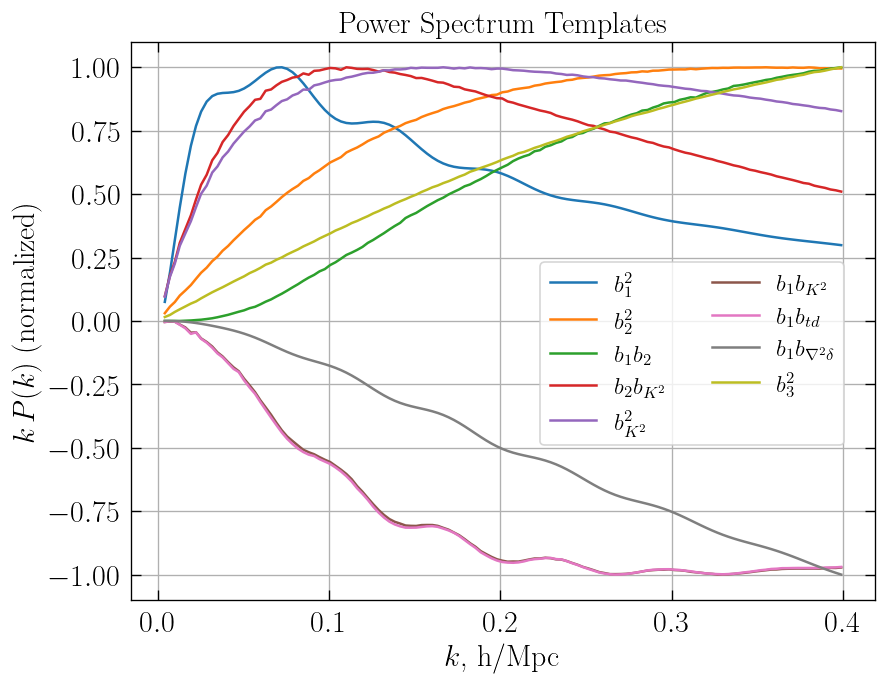

In [9]:
# coefficient: templates it multiplies (summed together for the plot)
P_groups = {r'$b_1^2$':                    ['b1b1', 'F2F2', 'b1F3'],
            r'$b_2^2$':                    ['b2b2'],
            r'$b_1 b_2$':                  ['b2F2'],
            r'$b_2 b_{K^2}$':              ['b2K2'],
            r'$b_{K^2}^2$':                ['K2K2'],
            r'$b_1 b_{K^2}$':              ['K2F2', 'b1K2_2'],
            r'$b_1 b_{td}$':               ['b1Otd'],
            r'$b_1 b_{\nabla^2\delta}$':   ['b1bk2'],
            r'$b_3^2$':                    ['b3b3']}

plt.figure(dpi=120)
for coeff, names in P_groups.items():
    kP_tmpl = kP * Wk**2 * sum(P_unbinned[name] for name in names)
    plt.plot(kP, kP_tmpl/np.max(np.abs(kP_tmpl)), label=coeff)
plt.xlabel(r'$k$, h/Mpc')
plt.ylabel(r'$k\,P(k)$ (normalized)')
plt.title('Power Spectrum Templates')
plt.legend(fontsize=14, ncol=2, loc=(0.55,0.277))
plt.grid()
plt.show()
# plt.savefig('v2_Plots/Power_Templates.pdf', bbox_inches='tight', format='pdf')
# plt.close()

## Power spectrum fit

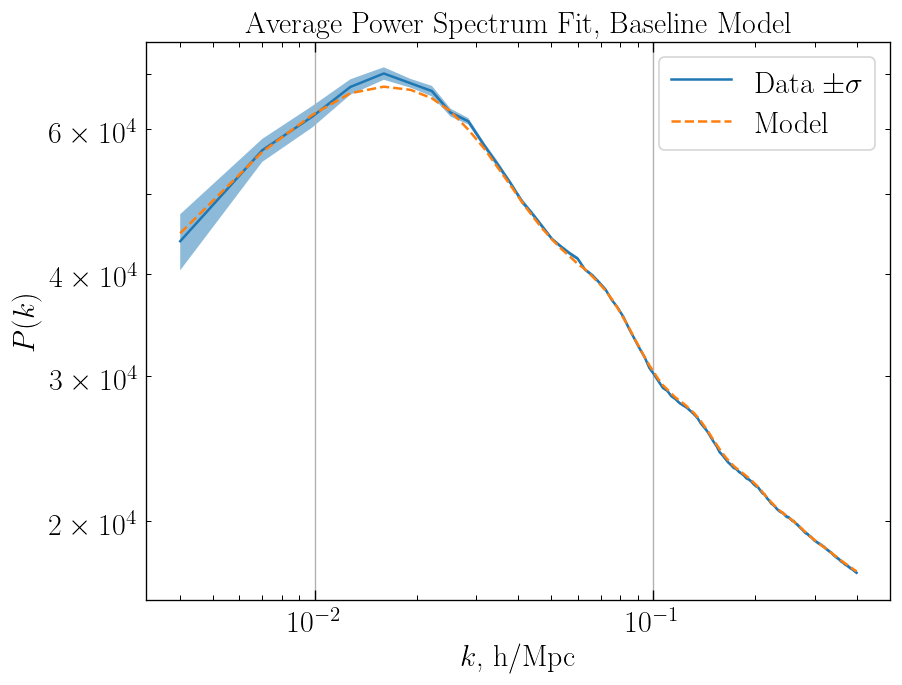

In [10]:
# Unbinned power spectrum (every k in the fit range), averaged over phases.
P_k = []
for ph in np.arange(phases):
    power_file = sim_root + 'Gala_ph0' + '{:02d}'.format(ph) + '/Gala_256_ps.dat'
    P_k.append(sims_power(power_file, kBins, numBins, Wk)[0][mask_P])
P_k = np.array(P_k)
k_plot = kP[mask_P]
W2 = Wk[mask_P]**2

# Unbinned model: same as P_model, but with the unbinned templates and noise terms.
def P_model_unbinned(params, noise):
    bPN, bPk2N, bBCN, bBPN, b1, b2, bK2, bOtd, bk2, b3 = params
    return W2 * (P_bias(params, P_unbinned)[mask_P] + bPN*noise + bPk2N*noise*k_plot**2)

data = np.mean(P_k, axis=0)
model = np.mean([P_model_unbinned(fit_params[ph], noises[ph]) for ph in np.arange(phases)], axis=0)
err = np.std(P_k, axis=0, ddof=1)/np.sqrt(phases)   # standard error of the mean

plt.figure(dpi=120)
plt.plot(k_plot, data, label=r'Data $\pm \sigma$')
plt.fill_between(k_plot, data - err, data + err, alpha=0.5)
plt.plot(k_plot, model, label='Model', linestyle='--')
plt.yscale('log')
plt.xscale('log')
plt.xlabel(r'$k$, h/Mpc')
plt.ylabel(r'$P(k)$')
plt.title('Average Power Spectrum Fit, ' + fit_label)
plt.legend()
plt.grid()
plt.show()
# plt.savefig('v2_Plots/Power_Fit.pdf', bbox_inches='tight', format='pdf')
# plt.close()

## Bispectrum

Slices of constant $k_1 + k_2 + k_3$ (the "circumference"). Change `circ_ind` to pick a slice.

In [11]:
circs = np.arange(33.5*kF, 127.5*kF, 2*kF)
circ_ind = 29

circ = circs[circ_ind]
plot_inds = np.where(np.abs(ksum - circ) < kF)[0]
ks_tri = tri.Triangulation(k2[plot_inds], k3[plot_inds])
circ_title = ', Circumference = ' + str(round(circ, 3)) + ' h/Mpc'

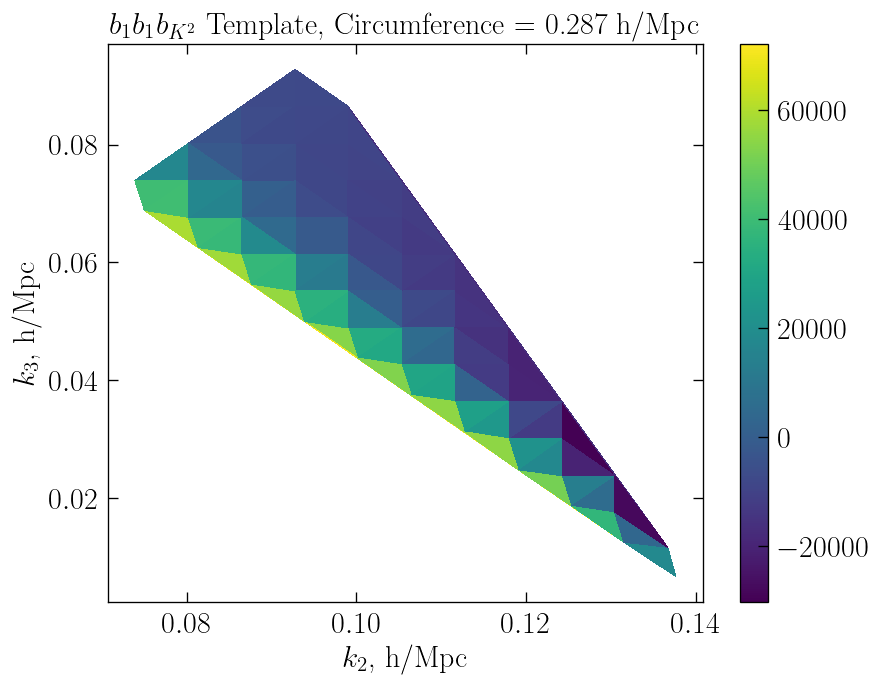

In [19]:
# Bispectrum template. Options: b1b1b2, b1b1K2, b1b1F2, b2b2b2, b1b2b3
template = 'b1b1K2'
template_name = r'$b_1b_1b_{K^2}$'

plt.figure(dpi=120)
plt.tripcolor(ks_tri, B_tmpl[template][plot_inds], shading='flat')
plt.colorbar()
plt.xlabel(r'$k_2$, h/Mpc')
plt.ylabel(r'$k_3$, h/Mpc')
plt.title(template_name + ' Template' + circ_title)
plt.show()
# plt.savefig('v2_Plots/b1b1K2.pdf', bbox_inches='tight', format='pdf')
# plt.close()

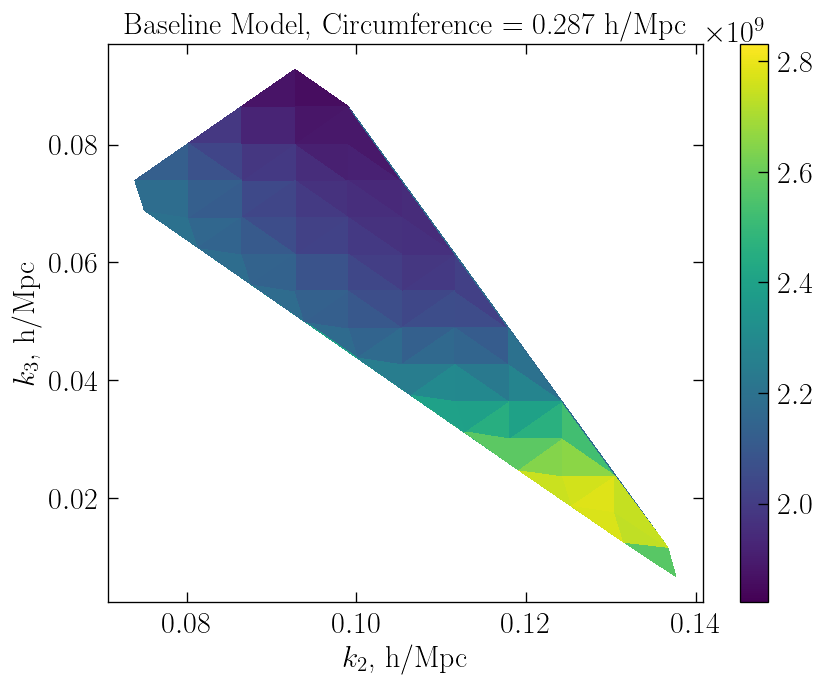

In [21]:
data_plot = np.mean(Bs, axis=0)[plot_inds]
model_plot = np.mean(B_models, axis=0)[plot_inds]
vmin = min(data_plot.min(), model_plot.min())
vmax = max(data_plot.max(), model_plot.max())

plt.figure(dpi=120)
plt.tripcolor(ks_tri, model_plot, shading='flat', vmin=vmin, vmax=vmax)
plt.colorbar()
plt.xlabel(r'$k_2$, h/Mpc')
plt.ylabel(r'$k_3$, h/Mpc')
plt.title(fit_label + circ_title)
plt.show()
# plt.savefig('v2_Plots/Model_Bispec.pdf', bbox_inches='tight', format='pdf')
# plt.close()

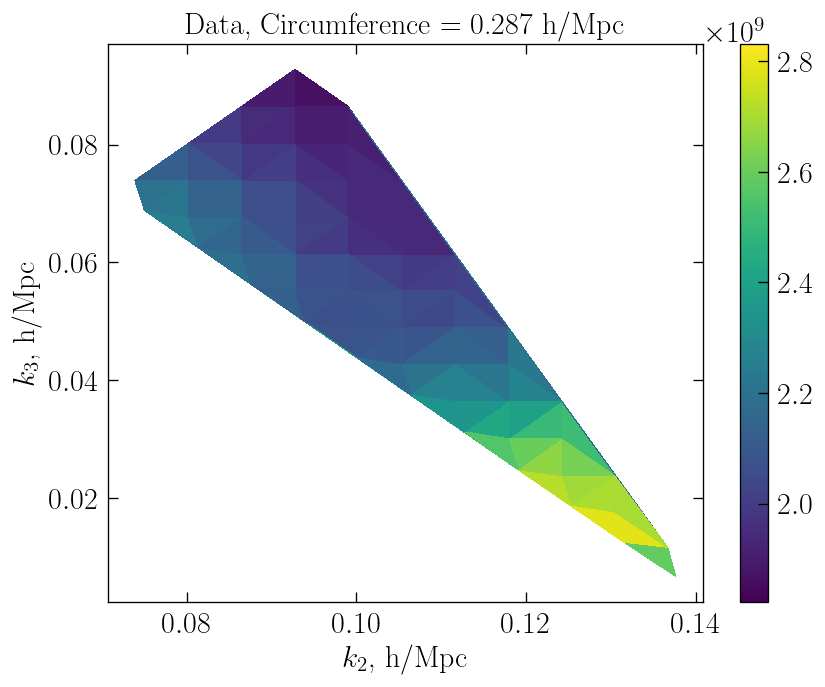

In [23]:
plt.figure(dpi=120)
plt.tripcolor(ks_tri, data_plot, shading='flat', vmin=vmin, vmax=vmax)
plt.colorbar()
plt.xlabel(r'$k_2$, h/Mpc')
plt.ylabel(r'$k_3$, h/Mpc')
plt.title('Data' + circ_title)
plt.show()
# plt.savefig('v2_Plots/Data_Bispec.pdf', bbox_inches='tight', format='pdf')
# plt.close()

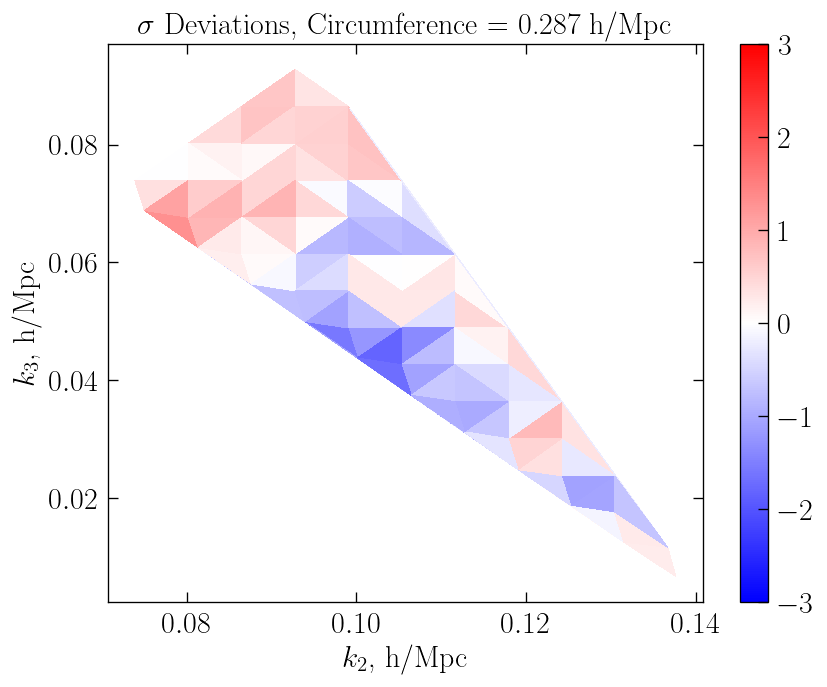

In [25]:
# (Data - Model) / std of the mean, both averaged over phases.
resid_plot = np.sqrt(phases) * (data_plot - model_plot)/std_B[plot_inds]

plt.figure(dpi=120)
plt.tripcolor(ks_tri, resid_plot, shading='flat', vmin=-3, vmax=3, cmap='bwr')
plt.colorbar()
plt.xlabel(r'$k_2$, h/Mpc')
plt.ylabel(r'$k_3$, h/Mpc')
plt.title(r'$\sigma$ Deviations' + circ_title)
plt.show()
# plt.savefig('v2_Plots/Residual_Bispec.pdf', bbox_inches='tight', format='pdf')
# plt.close()